# 02 · Model Training

In this notebook I fine-tune two pretrained models on the two training setups:

- ResNet-50 (CNN, 23.5M parameters), trained on SD 1.4 fakes and on SD 2.1 fakes
- ViT-S/16 (Vision Transformer, 21.7M parameters), trained on SD 1.4 fakes and on SD 2.1 fakes

ResNet-50 is my CNN baseline, since both Bird & Lotfi (2024) and Jiang (2024) used CNNs. I picked two models with a similar number of parameters so the comparison is about the architecture and not the model size.

Each of these four models is trained three times with different random seeds (42, 1 and 2). A single training run can be lucky or unlucky, so I report the average and the spread across the three runs instead of one number.

I also train one extra version of each model with blur and JPEG augmentation, following Wang et al. (2020), who found that this makes fake-image detectors more robust. This tests whether augmentation fixes the models' sensitivity to blur. That makes 16 training runs in total (12 main + 4 augmented).

Training details:
- The images are 32x32, so they are upsampled to 224x224 because that's the size both models were pretrained on.
- Optimiser is AdamW with a short warmup and then cosine decay. I also use mixed precision and gradient clipping to keep training stable on the T4.
- The main models only use horizontal flipping as augmentation. I avoided blur or JPEG augmentation for them on purpose, because those would hide the generator artefacts I'm testing for later.
- The augmented models also get, each with 50% probability, a Gaussian blur with a random strength between 0 and 3 pixels and JPEG compression with a random quality between 30 and 100.
- I keep the epoch with the lowest validation loss, and training stops early if it doesn't improve for 2 epochs.

In [2]:
# Environment setup
%pip install -q -U timm

import io
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from PIL import Image, ImageFilter
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
from google.colab import drive

# Colab's local disk is wiped when the session ends, so all outputs live in Google Drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/MAAI901_AIImageDetector")

DATA_DIR = PROJECT_DIR / "outputs" / "data"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
REAL, FAKE = 0, 1                      # FAKE is the positive class (the detection target)
LABEL_NAMES = {REAL: "REAL", FAKE: "FAKE"}
TRAIN_SETUPS = ("trainSD14", "trainSD21")
TEST_SETS = {                          # split name -> generator behind the fake images
    "test_sd14": "SD 1.4",
    "test_sd21": "SD 2.1",
    "test_sd30": "SD 3.0",
    "test_sd21blur": "SD 2.1 blurred",
}

# Two ImageNet-pretrained models of similar size (23.5M vs 21.7M parameters),
# so the comparison isolates architecture rather than capacity.
MODELS = {
    "resnet50": {"timm_id": "resnet50.a1_in1k", "family": "cnn",
                 "display_name": "ResNet-50 (CNN)", "lr": 1e-4, "timm_kwargs": {}},
    "vit_small": {"timm_id": "vit_small_patch16_224.augreg_in21k_ft_in1k", "family": "vit",
                  "display_name": "ViT-S/16 (Transformer)", "lr": 5e-5, "timm_kwargs": {}},
}
INPUT_SIZE = 224                       # resolution both backbones were pretrained at

SEEDS = (42, 1, 2)            # every main model is trained three times
AUG_SEEDS = (42,)             # augmented models are trained once


def run_name(setup, model_key, seed=42, augment=False):
    """File name of a training run. Seed-42 runs without augmentation keep the original names."""
    name = f"{setup}__{model_key}"
    if augment:
        name += "__aug"
    if seed != 42:
        name += f"__s{seed}"
    return name


# Order matters if a session is cut short: the augmented models come before the extra seeds
RUNS = ([(s, m, 42, False) for s in TRAIN_SETUPS for m in MODELS]
        + [(s, m, seed, True) for s in TRAIN_SETUPS for m in MODELS for seed in AUG_SEEDS]
        + [(s, m, seed, False) for seed in SEEDS if seed != 42 for s in TRAIN_SETUPS for m in MODELS])

EPOCHS = 6
BATCH_SIZE = 128
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05            # share of steps spent warming up the learning rate
GRAD_CLIP = 1.0
PATIENCE = 2                  # early-stopping patience in epochs
PRETRAINED = True
AUG_BLUR_MAX = 3.0            # augmentation settings from Wang et al. (2020)
AUG_JPEG_QUALITY = (30, 100)
AUG_PROB = 0.5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print(f"{len(RUNS)} training runs planned")

Mounted at /content/drive
Device: Tesla T4
16 training runs planned


## Model definition

In [3]:
class Detector(nn.Module):
    """Pretrained timm backbone with built-in preprocessing.

    Keeping the resize and normalisation inside the model guarantees that
    training, evaluation, Grad-CAM and the demo all preprocess identically.
    """

    def __init__(self, spec, input_size=INPUT_SIZE, pretrained=True):
        super().__init__()
        self.spec = dict(spec)
        self.family = spec["family"]
        self.input_size = input_size
        self.backbone = timm.create_model(spec["timm_id"], pretrained=pretrained,
                                          num_classes=2, **spec["timm_kwargs"])
        cfg = timm.data.resolve_model_data_config(self.backbone)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1), persistent=False)

    def preprocess(self, x):
        """Float NCHW in [0, 1] at any size -> normalised NCHW at input_size."""
        if x.shape[-2:] != (self.input_size, self.input_size):
            # 32x32 -> 224x224 on the GPU; bilinear interpolation adds no new detail
            x = F.interpolate(x, size=(self.input_size, self.input_size),
                              mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

    def forward(self, x):
        return self.backbone(self.preprocess(x))


def to_float(x_uint8):
    """uint8 NHWC (storage format) -> float NCHW in [0, 1] (model format)."""
    return x_uint8.permute(0, 3, 1, 2).float().div(255.0)

def load_split(name):
    """Return (images uint8 [N, 32, 32, 3], labels int64 [N]) for a saved split."""
    with np.load(DATA_DIR / f"{name}.npz") as z:
        return z["x"], z["y"]

## Training procedure

In [4]:
def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


def param_groups(model):
    """Weight decay on weight matrices only, not on biases, norms or position embeddings."""
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        skip = p.ndim <= 1 or name.endswith(".bias") or "pos_embed" in name or "cls_token" in name
        (no_decay if skip else decay).append(p)
    return [{"params": decay, "weight_decay": WEIGHT_DECAY},
            {"params": no_decay, "weight_decay": 0.0}]


def warmup_cosine(total_steps, warmup_steps):
    """Learning-rate multiplier: linear warmup, then cosine decay to zero."""
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    return factor


def blur_jpeg_augment(batch_uint8, rng):
    """Random Gaussian blur and JPEG compression, each applied with probability AUG_PROB (Wang et al., 2020)."""
    out = batch_uint8.numpy().copy()
    for i in range(len(out)):
        img = Image.fromarray(out[i])
        if rng.random() < AUG_PROB:
            img = img.filter(ImageFilter.GaussianBlur(radius=rng.uniform(0, AUG_BLUR_MAX)))
        if rng.random() < AUG_PROB:
            buf = io.BytesIO()
            img.save(buf, format="JPEG", quality=int(rng.integers(AUG_JPEG_QUALITY[0], AUG_JPEG_QUALITY[1] + 1)))
            img = Image.open(buf).convert("RGB")
        out[i] = np.asarray(img)
    return torch.from_numpy(out)


@torch.no_grad()
def validate(model, X, Y, use_amp, batch_size=512):
    model.eval()
    logits = []
    for i in range(0, len(X), batch_size):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits.append(model(to_float(X[i:i + batch_size])).float())
    logits = torch.cat(logits)
    probs = logits.softmax(1)[:, FAKE].cpu().numpy()
    y = Y.cpu().numpy()
    return {"val_loss": F.cross_entropy(logits, Y).item(),
            "val_acc": float(((probs >= 0.5) == y).mean()),
            "val_auroc": float(roc_auc_score(y, probs))}


def train_run(setup, model_key, seed=42, augment=False):
    """Fine-tune one model on one training setup; finished runs are reused, not repeated."""
    name = run_name(setup, model_key, seed, augment)
    ckpt_path = MODEL_DIR / f"{name}.pt"
    summary_path = MODEL_DIR / f"{name}.summary.json"
    if ckpt_path.exists() and summary_path.exists():
        print(f"[{name}] checkpoint found - reusing it")
        summary = json.loads(summary_path.read_text())
        return {**summary, "seed": seed, "augment": augment}

    seed_everything(seed)
    spec = MODELS[model_key]
    use_amp = device.type == "cuda"
    aug_rng = np.random.default_rng(seed)

    # The whole split (~60 MB as uint8) fits on the GPU, so no DataLoader is needed
    X, Y = (torch.from_numpy(a).to(device) for a in load_split(f"{setup}_train"))
    Xv, Yv = (torch.from_numpy(a).to(device) for a in load_split(f"{setup}_val"))

    model = Detector(spec, pretrained=PRETRAINED).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(param_groups(model), lr=spec["lr"])
    steps_per_epoch = math.ceil(len(X) / BATCH_SIZE)
    total_steps = steps_per_epoch * EPOCHS
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, warmup_cosine(total_steps, max(1, int(WARMUP_FRAC * total_steps))))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    generator = torch.Generator().manual_seed(seed)
    print(f"[{name}] {spec['timm_id']} | {n_params / 1e6:.1f}M parameters | "
          f"{len(X):,} train / {len(Xv):,} val images | blur/JPEG augmentation: {augment}")

    history, best_loss, best_epoch, stale = [], float("inf"), 0, 0
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X), generator=generator).to(device)
        running, seen, epoch_start = 0.0, 0, time.time()
        bar = tqdm(range(steps_per_epoch), desc=f"epoch {epoch}/{EPOCHS}", leave=False)
        for step in bar:
            idx = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
            xb_uint8, yb = X[idx], Y[idx]
            if augment:
                xb_uint8 = blur_jpeg_augment(xb_uint8.cpu(), aug_rng).to(device)
            xb = to_float(xb_uint8)
            flip = torch.rand(len(xb), device=device) < 0.5          # random horizontal flips
            xb = torch.where(flip[:, None, None, None], xb.flip(-1), xb)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                loss = F.cross_entropy(model(xb), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError("Loss diverged - the learning rate is too high.")
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item() * len(xb)
            seen += len(xb)
            bar.set_postfix(loss=f"{running / seen:.4f}")

        row = {"epoch": epoch, "train_loss": running / seen, "epoch_time_s": time.time() - epoch_start,
               **validate(model, Xv, Yv, use_amp)}
        history.append(row)
        improved = row["val_loss"] < best_loss - 1e-4
        print(f"  epoch {epoch}: train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | "
              f"val_acc {row['val_acc']:.4f} | val_auroc {row['val_auroc']:.4f}"
              + ("  <- best" if improved else ""))
        if improved:
            best_loss, best_epoch, stale = row["val_loss"], epoch, 0
            torch.save({"state_dict": model.state_dict(), "spec": spec, "input_size": INPUT_SIZE,
                        "setup": setup, "seed": seed, "augment": augment, "epoch": epoch, "val": row},
                       ckpt_path)
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"  early stopping after epoch {epoch}")
                break

    pd.DataFrame(history).to_csv(MODEL_DIR / f"{name}.history.csv", index=False)
    best = history[best_epoch - 1]
    summary = {"setup": setup, "model": model_key, "display_name": spec["display_name"],
               "timm_id": spec["timm_id"], "params": n_params, "lr": spec["lr"],
               "best_epoch": best_epoch, "epochs_run": len(history),
               "train_time_min": (time.time() - start) / 60,
               **{k: best[k] for k in ("val_loss", "val_acc", "val_auroc")}}
    summary_path.write_text(json.dumps(summary, indent=2))
    del X, Y, Xv, Yv, model, optimizer
    torch.cuda.empty_cache()
    return {**summary, "seed": seed, "augment": augment}

## Training runs

The cell below runs all 16 training runs one after another (about 1.5 hours on a T4). The four seed-42 main runs from the first round of training are reused.

In [5]:
summaries = [train_run(*run) for run in RUNS]
summary = pd.DataFrame(summaries)
summary.to_csv(RESULTS_DIR / "training_summary.csv", index=False)
summary[["setup", "display_name", "seed", "augment", "best_epoch", "epochs_run",
         "val_acc", "val_auroc", "train_time_min"]].round(4)

[trainSD14__resnet50] checkpoint found - reusing it
[trainSD14__vit_small] checkpoint found - reusing it
[trainSD21__resnet50] checkpoint found - reusing it
[trainSD21__vit_small] checkpoint found - reusing it


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

[trainSD14__resnet50__aug] resnet50.a1_in1k | 23.5M parameters | 20,000 train / 3,980 val images | blur/JPEG augmentation: True


epoch 1/6:   0%|          | 0/157 [00:00<?, ?it/s]

...

epoch 5/6:   0%|          | 0/157 [00:00<?, ?it/s]

  epoch 5: train_loss 0.0002 | val_loss 0.0200 | val_acc 0.9942 | val_auroc 0.9998  <- best


epoch 6/6:   0%|          | 0/157 [00:00<?, ?it/s]

  epoch 6: train_loss 0.0001 | val_loss 0.0195 | val_acc 0.9945 | val_auroc 0.9998  <- best


,setup,display_name,seed,augment,best_epoch,epochs_run,val_acc,val_auroc,train_time_min
0,trainSD14,ResNet-50 (CNN),42,False,5,6,0.9540,0.9899,7.1693
1,trainSD14,ViT-S/16 (Transformer),42,False,4,6,0.9867,0.9986,6.5329
2,trainSD21,ResNet-50 (CNN),42,False,5,6,0.9748,0.9976,7.1143
3,trainSD21,ViT-S/16 (Transformer),42,False,3,5,0.9948,0.9998,5.4138
4,trainSD14,ResNet-50 (CNN),42,True,5,6,0.9307,0.9832,7.4567
5,trainSD14,ViT-S/16 (Transformer),42,True,6,6,0.9789,0.9984,6.9327
6,trainSD21,ResNet-50 (CNN),42,True,6,6,0.9620,0.9941,7.5372
7,trainSD21,ViT-S/16 (Transformer),42,True,4,6,0.9890,0.9996,6.8768
8,trainSD14,ResNet-50 (CNN),1,False,6,6,0.9513,0.9897,7.1730
9,trainSD14,ViT-S/16 (Transformer),1,False,5,6,0.9842,0.9984,6.5603


### Reading the training output

Each block starts with the run's name, for example `trainSD14__vit_small__s1`: the training setup (which generator the fake images came from), the model, and the seed (no suffix means seed 42). Runs ending in `__aug` use blur and JPEG augmentation.

After every epoch, four values are printed:

- `train_loss`: the average cross-entropy loss on the training images during that epoch
- `val_loss`: the loss on the validation images, which the model never trains on
- `val_acc`: the share of validation images classified correctly (REAL vs FAKE)
- `val_auroc`: how well the model separates real from fake images regardless of the 0.5 threshold (1.0 = perfect separation)

`<- best` marks the epoch with the lowest validation loss so far. Only that epoch is saved as the checkpoint, so a later epoch that starts to overfit does not replace a better one. If the validation loss doesn't improve for 2 epochs in a row, training stops early.

The Hugging Face and `lr_scheduler.step()` warnings don't affect the results: the first only means the pretrained weights were downloaded without logging in, and the second appears because mixed-precision training sometimes skips the very first optimiser step while it calibrates the loss scaling.

## Validation results across seeds

In [6]:
main = summary[~summary.augment]
across_seeds = (main.groupby(["setup", "display_name"])[["val_acc", "val_auroc", "best_epoch", "train_time_min"]]
                .agg(["mean", "std"]))
across_seeds.to_csv(RESULTS_DIR / "training_across_seeds.csv")
across_seeds.round(4)

val_acc         val_auroc         best_epoch  \
                                    mean     std      mean     std       mean   
setup     display_name                                                          
trainSD14 ResNet-50 (CNN)         0.9502  0.0045    0.9897  0.0002     5.3333   
          ViT-S/16 (Transformer)  0.9804  0.0088    0.9976  0.0015     3.3333   
trainSD21 ResNet-50 (CNN)         0.9754  0.0008    0.9976  0.0001     5.3333   
          ViT-S/16 (Transformer)  0.9946  0.0001    0.9998  0.0000     4.3333   

                                         train_time_min          
                                     std           mean     std  
setup     display_name                                           
trainSD14 ResNet-50 (CNN)         0.5774         7.1596  0.0202  
          ViT-S/16 (Transformer)  2.0817         5.4817  1.8445  
trainSD21 ResNet-50 (CNN)         0.5774         7.1455  0.0271  
          ViT-S/16 (Transformer)  1.5275         6.1500  0.6378

**What this shows.** The ViT reached higher validation accuracy than the CNN in every seed and in both setups (98.0% vs 95.0% on SD 1.4, 99.5% vs 97.5% on SD 2.1), so its advantage on the generator it was trained on is not down to one lucky run. The ViT is less stable across seeds, though: its best epoch varies more, and the SD 1.4 run with seed 2 stopped after three epochs because its validation loss rose after epoch 1 while its accuracy was still improving. All runs take a similar time (about 5 to 7 minutes each).

## Training curves

Seed-42 runs, with the augmented runs shown as dotted lines. Validation loss falling and then levelling off indicates healthy training; validation loss rising while training loss keeps falling would indicate overfitting, which early stopping guards against.

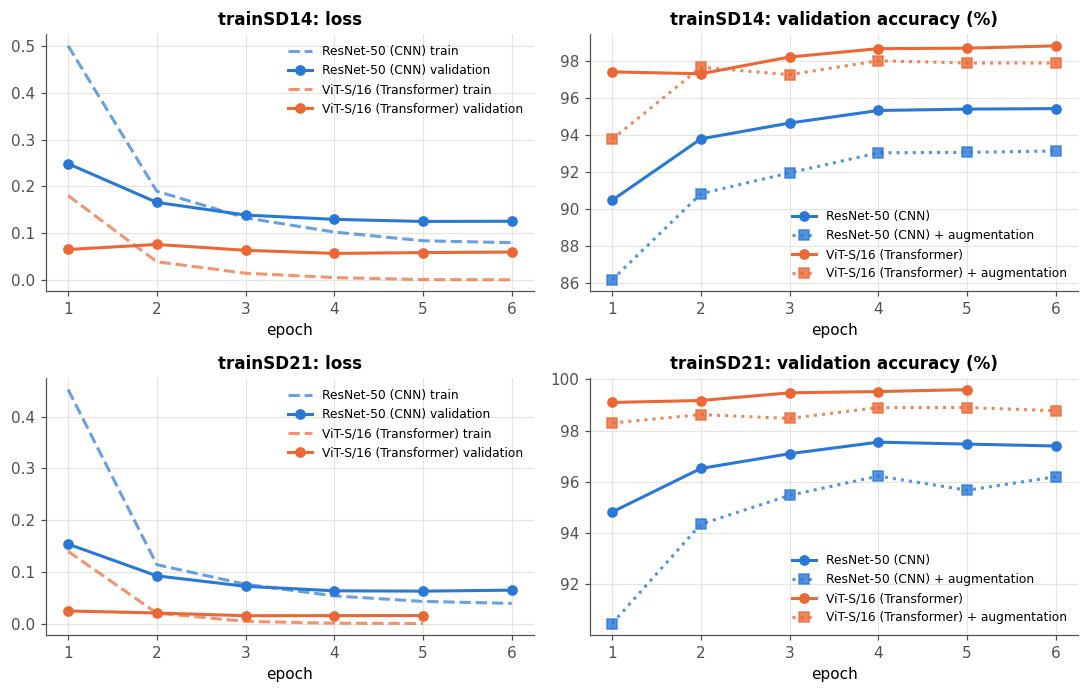

In [7]:
# One fixed colour per model across every figure
MODEL_COLORS = {"resnet50": "#2a78d6", "vit_small": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4df",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})

fig, axes = plt.subplots(len(TRAIN_SETUPS), 2, figsize=(10, 3.2 * len(TRAIN_SETUPS)), squeeze=False)
for r, setup in enumerate(TRAIN_SETUPS):
    for model_key, spec in MODELS.items():
        color, name = MODEL_COLORS[model_key], spec["display_name"]
        h = pd.read_csv(MODEL_DIR / f"{run_name(setup, model_key)}.history.csv")
        axes[r, 0].plot(h.epoch, h.train_loss, "--", color=color, alpha=0.7, label=f"{name} train")
        axes[r, 0].plot(h.epoch, h.val_loss, "-o", color=color, label=f"{name} validation")
        axes[r, 1].plot(h.epoch, h.val_acc * 100, "-o", color=color, label=name)
        aug_file = MODEL_DIR / f"{run_name(setup, model_key, augment=True)}.history.csv"
        if aug_file.exists():
            ha = pd.read_csv(aug_file)
            axes[r, 1].plot(ha.epoch, ha.val_acc * 100, ":s", color=color, alpha=0.8, label=f"{name} + augmentation")
    axes[r, 0].set(title=f"{setup}: loss", xlabel="epoch")
    axes[r, 1].set(title=f"{setup}: validation accuracy (%)", xlabel="epoch")
    axes[r, 0].legend(fontsize=8)
    axes[r, 1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_training_curves.png")
plt.show()

**What this shows.** The ViT's validation loss is already low after the first epoch, which suggests its pretrained features transfer to this task almost immediately, while the CNN improves more gradually. The ViT's training loss drops close to zero, a sign that it starts memorising the training images; keeping the epoch with the lowest validation loss prevents this from affecting the saved model. The augmented models (dotted) are slightly less accurate on clean validation images, which is the expected cost of training on blurred and compressed images.